# La exposición de un swap: trayectorias de Hull-White, EE, PFE y neteo

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** los temas 06 y 07 del índice (capital de cartera y riesgo de mercado), o ninguno si lees el código
- **Tiempo de lectura:** unos 40 minutos

**Pregunta:** Si la contraparte de un swap pagador a 10 años incumpliera en una fecha futura, ¿cuánto le debería al banco en promedio y en un mal caso, y cuánto de esa exposición desaparece al netear el swap con otros tres?

## Objetivos

Al terminar este notebook puedes:

- decir qué es un modelo de tasa corta de un factor y reconstruir el que usa Contraste (Hull-White, ajustado a la curva de hoy) desde la curva y la calibración versionadas;
- valorar un swap de tasas en cada trayectoria simulada y en cada fecha, y leer la nube de valores como una distribución;
- calcular la exposición esperada (EE), la exposición futura potencial (PFE), la exposición positiva esperada (EPE) y su versión efectiva (EEPE), cada una desde su definición;
- mostrar por qué el neteo se toma sobre la suma de los valores y no sobre la suma de las partes positivas, y medir el beneficio de neteo;
- leer una exposición en dólares: su máximo, el año en que ocurre y cuánto de ella elimina el neteo de cuatro swaps.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.ccr import exposure as ex
from riskvalidation.ccr import hw1f
from riskvalidation.ccr import swaps as sw

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Los datos son el caso C12 (riesgo de crédito de contraparte), tal como Contraste lo versiona. La curva es la curva de rendimientos a la par del Tesoro de EE. UU. del 2025-09-30 (clase de licencia `mirror-allowed`, https://home.treasury.gov/resource-center/data-chart-center/interest-rates/), convertida en tasas cero con capitalización continua. El swap es **sintético**: un pagador a 10 años de 10 millones de USD cuya tasa fija es el rendimiento a la par a su vencimiento, redondeado a 10 pb. Los parámetros `a` y `sigma` se estimaron con 35 años de la tasa del Tesoro a 3 meses, usando solo datos anteriores a la fecha de la curva.

- **Archivos que se leen:** `data/derived/C12/single-swap.json` (un swap, clave `outputs`) y `data/derived/C12/netting-set.json` (la misma curva con cuatro swaps). Ambos son documentos del esquema `contraste.case/v1`.
- **Estado de verdad:** `synthetic-calibrated`. Las entradas de mercado son reales, las operaciones son convenciones del caso y cada una lleva la etiqueta `convention`.
- **Por qué cuatro swaps para uno:** la simulación la comparten todas las variantes de C12 y los números aleatorios dependen de la forma de la grilla de tiempo. Para reproducir el cálculo reconstruimos la grilla que usó, que contiene las fechas de reinicio de los cuatro swaps.

La celda siguiente carga ambos documentos e imprime la curva, la calibración y la operación.

In [2]:
# Cargar los dos documentos versionados de C12 (el notebook está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C12"
single = json.loads((derived / "single-swap.json").read_text(encoding="utf-8"))
netting = json.loads((derived / "netting-set.json").read_text(encoding="utf-8"))
out = single["outputs"]
cal = out["calibration_used"]
trade = out["book"]["trades"][0]

print("fecha de la curva:", out["curve"]["curve_date"], "|", out["curve"]["source"])
for point in out["curve"]["points"][::3]:
    print(f"  plazo {point['tenor_years']:8.4f} a | rendimiento a la par {point['par_yield']:.4f}"
          f" | tasa cero {point['zero_rate']:.6f}")
print("calibración: a =", round(cal["a"], 6), "| sigma =", round(cal["sigma"], 6),
      "| observaciones:", cal["n_obs"], "|", cal["sample_start"], "a", cal["sample_end"])
side = "pagador" if trade["side"] == "payer" else "receptor"
print("operación:", trade["trade_id"], side, trade["notional"]["amount"], trade["notional"]["currency"],
      "| tasa fija", trade["fixed_rate"], "| vencimiento", trade["maturity_years"], "a")

fecha de la curva: 2025-09-30 | US Treasury daily par yield curve (home.treasury.gov)
  plazo   0.0833 a | rendimiento a la par 0.0420 | tasa cero 0.041927
  plazo   0.3333 a | rendimiento a la par 0.0398 | tasa cero 0.039538
  plazo   2.0000 a | rendimiento a la par 0.0360 | tasa cero 0.035657
  plazo   7.0000 a | rendimiento a la par 0.0393 | tasa cero 0.039180
  plazo  30.0000 a | rendimiento a la par 0.0473 | tasa cero 0.048499
calibración: a = 0.167466 | sigma = 0.008798 | observaciones: 8939 | 1990-01-02 a 2025-09-29
operación: SW-1 pagador 10000000.0 USD | tasa fija 0.042 | vencimiento 10.0 a


## Método

### Paso 1: la curva y el modelo

La tasa corta del modelo de Hull-White de un factor es la suma de una parte determinista y un estado con reversión a la media (Hull y White, 1990; Brigo et al., 2008):

$$r_t = \varphi(t) + x_t, \qquad dx_t = -a\,x_t\,dt + \sigma\,dW_t, \qquad x_0 = 0$$

La parte determinista se elige para que el modelo valore exactamente la curva de descuento de hoy:

$$\varphi(t) = f(0,t) + \tfrac12\left(\frac{\sigma\,(1 - e^{-a t})}{a}\right)^2$$

con $f(0,t)$ la tasa forward instantánea de la curva de hoy. Los precios de bonos son afines en la tasa corta, $P(t,T) = A(t,T)\,e^{-B(t,T)\,r_t}$ con $B(t,T) = (1 - e^{-a(T-t)})/a$. `curve_functions`, del motor, convierte la curva cero en dos funciones, el factor de descuento de hoy $P(0,t)$ y el forward $f(0,t)$. La celda siguiente las construye, verifica los factores de descuento contra $e^{-z t}$ e imprime $\varphi$ junto al forward para mostrar el tamaño del término de convexidad.

In [3]:
# Función de descuento y forward de hoy desde la curva cero, y luego la función de ajuste phi de Hull-White
tenors = np.array([p["tenor_years"] for p in out["curve"]["points"]])
zeros = np.array([p["zero_rate"] for p in out["curve"]["points"]])
a, sigma = cal["a"], cal["sigma"]
p0, forward = hw1f.curve_functions(zeros, tenors)

t = np.array([1.0, 5.0, 10.0])
phi = hw1f.phi(t, a, sigma, forward)
print("t (años)                :", t)
print("P(0,t) del motor  :", np.round(p0(t), 8))
print("exp(-z t) sobre la curva:", np.round(np.exp(-np.interp(t, tenors, zeros) * t), 8))
print("forward f(0,t)        :", np.round(forward(t), 6))
print("phi(t)                       :", np.round(phi, 6))
print("phi(t) - f(0,t) (término de convexidad):", np.round(phi - forward(t), 6))

t (años)                : [ 1.  5. 10.]
P(0,t) del motor  : [0.96420438 0.83057003 0.65864838]
exp(-z t) sobre la curva: [0.96420438 0.83057003 0.65864838]
forward f(0,t)        : [0.035657 0.042256 0.04892 ]
phi(t)                       : [0.03569  0.0427   0.049831]
phi(t) - f(0,t) (término de convexidad): [3.30e-05 4.44e-04 9.11e-04]


### Paso 2: las trayectorias

El estado $x_t$ se simula de forma exacta (su ley no depende del paso) con variables antitéticas, de modo que la mitad de las trayectorias es el espejo de la otra mitad y la media muestral de $x_t$ es cero. La grilla de tiempo es la unión de las fechas del informe, las fechas de cierre de las variantes con garantía (10 y 20 días hábiles, como 14 y 28 días corridos en el eje 30/360 del caso) y las fechas de reinicio de los swaps. La celda siguiente construye los cuatro swaps desde el documento del conjunto de neteo, arma esa grilla y simula la tasa corta con el número de trayectorias y la semilla del propio caso.

In [4]:
# Los cuatro swaps del documento del conjunto de neteo, la grilla de simulación del cálculo y la tasa corta simulada
named = out["named_parameters"]
report = np.array(named["time_grid_years"]["value"])
main = np.concatenate([[0.0], report])
closeouts = [14 / 360, 28 / 360]
swaps = [
    sw.Swap(tr["trade_id"], tr["notional"]["amount"], tr["fixed_rate"], tr["side"] == "payer",
            tr["start_years"], tr["maturity_years"], tr["fixed_frequency_per_year"])
    for tr in netting["outputs"]["book"]["trades"]
]
merged = np.unique(np.round(np.concatenate([main] + [main + d for d in closeouts]), 12))
grid = sw.simulation_grid(merged, swaps)
n_paths, seed = named["path_count"]["value"], named["seed"]["value"]
r = hw1f.simulate_short_rate(grid, a, sigma, forward, n_paths, seed)

k5 = int(np.searchsorted(grid, 5.0 - 1e-9))
ou_std = sigma * np.sqrt((1 - np.exp(-2 * a * 5.0)) / (2 * a))
print("fechas del informe:", report.size, "| puntos de la grilla:", grid.size,
      "| trayectorias:", r.shape[0], "| semilla:", seed)
print("mayor brecha entre la media de r y phi:",
      float(np.max(np.abs(r.mean(axis=0) - hw1f.phi(grid, a, sigma, forward)))))
print("desviación de r a 5 años, simulada:", round(float(r[:, k5].std()), 6),
      "| ley de Ornstein-Uhlenbeck:", round(float(ou_std), 6))

fechas del informe: 33 | puntos de la grilla: 102 | trayectorias: 20000 | semilla: 42
mayor brecha entre la media de r y phi: 1.9539925233402755e-14
desviación de r a 5 años, simulada: 0.01356 | ley de Ornstein-Uhlenbeck: 0.013705


La celda siguiente dibuja treinta de las trayectorias simuladas de la tasa corta con la media ajustada y una banda de dos desviaciones estándar del estado, para ver la aleatoriedad que moverá el swap.

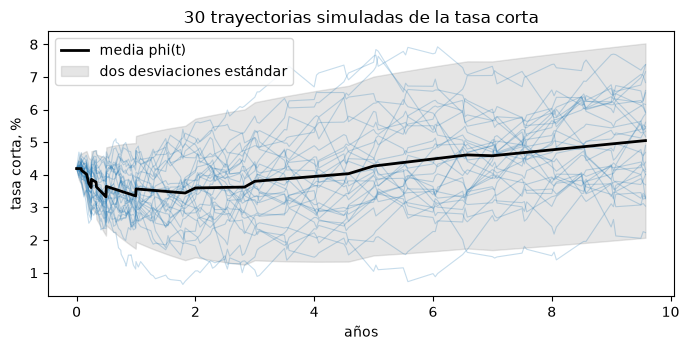

In [5]:
# Dibujar 30 trayectorias de la tasa corta con la media phi(t) y una banda de dos desviaciones estándar
fig, ax = plt.subplots(figsize=(7, 3.6))
spread = sigma * np.sqrt((1 - np.exp(-2 * a * grid)) / (2 * a))
mean_rate = hw1f.phi(grid, a, sigma, forward)
ax.plot(grid, 100 * r[:30].T, color="tab:blue", alpha=0.25, lw=0.8)
ax.plot(grid, 100 * mean_rate, color="black", lw=2, label="media phi(t)")
ax.fill_between(grid, 100 * (mean_rate - 2 * spread), 100 * (mean_rate + 2 * spread), color="grey", alpha=0.2,
                label="dos desviaciones estándar")
ax.set_xlabel("años")
ax.set_ylabel("tasa corta, %")
ax.set_title("30 trayectorias simuladas de la tasa corta")
ax.legend()
fig.tight_layout()
plt.show()

La figura muestra treinta de las 20.000 trayectorias simuladas de la tasa corta. Se abren alrededor de la curva negra, la media ajustada $\varphi(t)$, y la banda gris marca dos desviaciones estándar del estado $x_t$. La banda se ensancha rápido y luego se aplana, porque la reversión a la media $a$ devuelve cada trayectoria hacia el centro: por eso la incertidumbre del modelo sobre una tasa deja de crecer con el horizonte. La figura todavía no muestra el swap, solo la aleatoriedad que moverá su valor, y no dice si las tasas reales se comportan así (el notebook 06 lo prueba).

### Paso 3: el modelo reprecia la curva

Un modelo de exposición solo sirve si primero reproduce los precios de hoy. En $t=0$ el estado es cero y $r_0=\varphi(0)$, así que la fórmula $P(0,T) = A(0,T)\,e^{-B(0,T)\,\varphi(0)}$ debe devolver el factor de descuento de la curva. `bond_price`, del motor, la evalúa; la celda siguiente la compara con $P(0,T)$ en tres vencimientos.

In [6]:
# Revalorar los factores de descuento en t = 0 con el modelo y compararlos con la curva
r0 = hw1f.phi(np.array(0.0), a, sigma, forward).reshape(1)
for maturity in (1.0, 5.0, 10.0):
    model = hw1f.bond_price(r0, 0.0, maturity, a, sigma, p0, forward)[0]
    curve = float(p0(np.array(maturity)))
    print(f"T = {maturity:4.1f} | modelo {model:.12f} | curva {curve:.12f} | diferencia {model - curve:.1e}")

T =  1.0 | modelo 0.964204378531 | curva 0.964204378531 | diferencia 1.1e-16
T =  5.0 | modelo 0.830570031476 | curva 0.830570031476 | diferencia 1.1e-16
T = 10.0 | modelo 0.658648375416 | curva 0.658648375416 | diferencia 0.0e+00


### Paso 4: el valor del swap en cada trayectoria

El swap paga la tasa fija en sus fechas fijas y recibe la pata flotante, que se reinicia con el mismo calendario. En una trayectoria, el valor en la fecha $t$ para el banco (un swap pagador) es la pata flotante menos la pata fija, donde cada pago restante $T_i$ se descuenta con el precio de bono del modelo $P(t,T_i)$ a la tasa corta de esa trayectoria y fecha. Entre dos reinicios el cupón ya fijado se conoce en la trayectoria, y el motor lo lee de la misma trayectoria. `swap_values_on_grid` hace todo esto para una lista de swaps y devuelve un arreglo de forma (swap, trayectoria, fecha). La tasa fija se fijó en el rendimiento a la par, por lo que el valor en $t=0$ es pequeño pero no exactamente cero (la tasa se redondeó a 10 pb). La celda siguiente valora los cuatro swaps y compara el primero con la tasa par.

In [7]:
# Valorar los cuatro swaps en cada trayectoria y fecha, y el primero contra la tasa par en t = 0
values = sw.swap_values_on_grid(swaps, grid, r, a, sigma, p0, forward)
numeraire = hw1f.bank_account(grid, r, a, sigma, p0, forward)
ix = np.searchsorted(grid, report - sw.TIME_TOL)
par = sw.par_fixed_rate(10.0, 2, p0)

print("arreglo de valores (swap, trayectoria, fecha):", values.shape)
print("tasa fija par del swap a 10 años:", round(par, 6),
      "| tasa en la operación:", trade["fixed_rate"])
print("valor de SW-1 en t = 0, igual en toda trayectoria:",
      round(float(values[0, 0, 0]), 2))
for years in (1.0, 5.0):
    k = int(np.searchsorted(grid, years - 1e-9))
    q = np.percentile(values[0, :, k], [5, 50, 95])
    print(f"valor de SW-1 a {years:.0f} a, 5% / 50% / 95%:", np.round(q, 0))

arreglo de valores (swap, trayectoria, fecha): (4, 20000, 102)
tasa fija par del swap a 10 años: 0.041601 | tasa en la operación: 0.042
valor de SW-1 en t = 0, igual en toda trayectoria: -32701.09
valor de SW-1 a 1 a, 5% / 50% / 95%: [-533575.   25762.  553402.]
valor de SW-1 a 5 a, 5% / 50% / 95%: [-475109.  234506.  894008.]


### Paso 5: exposición esperada, PFE y las medidas efectivas

La exposición a la contraparte es la parte positiva del valor, porque si la contraparte incumple el banco pierde solo cuando se le debe dinero. Las definiciones de las medidas de exposición (CRE53; metodología de ORE) son, con $V$ el valor del conjunto de neteo y $N$ el numerario (la cuenta bancaria, $N(0)=1$):

$$\mathrm{EE}(t) = \mathbb{E}\left[\frac{\max(V(t),0)}{N(t)}\right], \qquad \mathrm{PFE}_\alpha(t) = \inf\{x : F_t(x) \ge \alpha\}^+$$

`expected_exposure`, del motor, devuelve esta EE descontada y su error estándar de Monte Carlo. Contraste informa la EE sin descontar (estilo Basilea) en la medida $t$-forward, que es la EE descontada dividida por $P(0,t)$; esa es la cantidad que da la fórmula analítica de la swaption (notebook 06) y la que reproduce ORE (notebook 07). La PFE es el cuantil de 95% del valor, con un error por remuestreo. Durante el primer año:

$$\mathrm{EE\ efectiva}(t_k) = \max(\mathrm{EE\ efectiva}(t_{k-1}),\ \mathrm{EE}(t_k)), \qquad \mathrm{EEPE} = \frac{1}{1}\sum_{t_k \le 1} \mathrm{EE\ efectiva}(t_k)\,\Delta t_k$$

La celda siguiente calcula todas para el primer swap e imprime los máximos y los promedios del primer año.

In [8]:
# EE (descontada, luego medida forward), PFE, EE efectiva, EPE y EEPE del swap único
p0r = p0(report)
v1 = values[0][:, ix]
ee_d, ee_d_se = ex.expected_exposure(v1, numeraire[:, ix])
ee, ee_se = ee_d / p0r, ee_d_se / p0r
pfe, pfe_se = ex.pfe(v1, named["pfe_quantile"]["value"], seed=seed, n_bootstrap=50)
eff = ex.effective_ee(ee)
epe, eepe = ex.epe(report, ee), ex.effective_epe(report, eff)
k1 = np.searchsorted(report, 1.0 - 1e-9)

print("máximo de la EE:", round(float(ee.max()), 0), "en", float(report[ee.argmax()]), "a")
print("máximo de la PFE95:", round(float(pfe.max()), 0), "en", float(report[pfe.argmax()]), "a")
print("EE a 1 a:", round(float(ee[k1]), 0), "+/-", round(float(ee_se[k1]), 0))
print("EPE:", round(epe, 2), "| EEPE:", round(eepe, 2), "| error de Monte Carlo de la EEPE:",
      round(out["exposure"]["eepe"]["mc_se"], 2))

máximo de la EE: 294524.0 en 5.0 a
máximo de la PFE95: 901804.0 en 4.5 a
EE a 1 a: 141414.0 +/- 1374.0
EPE: 87550.9 | EEPE: 87550.9 | error de Monte Carlo de la EEPE: 570.58


La celda siguiente dibuja cuarenta trayectorias del valor de SW-1 junto con su EE y su PFE de 95%.

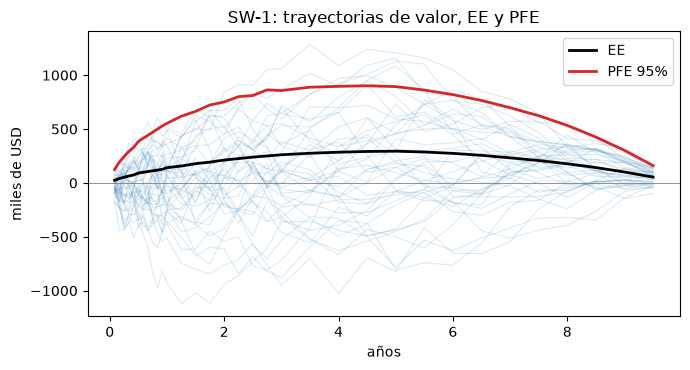

In [9]:
# Dibujar las trayectorias de valor de SW-1 con su EE y su PFE de 95%
fig, ax = plt.subplots(figsize=(7, 3.8))
for path in v1[:40]:
    ax.plot(report, path / 1e3, color="tab:blue", alpha=0.15, lw=0.8)
ax.plot(report, ee / 1e3, color="black", lw=2, label="EE")
ax.plot(report, pfe / 1e3, color="tab:red", lw=2, label="PFE 95%")
ax.axhline(0, color="grey", lw=0.6)
ax.set_xlabel("años")
ax.set_ylabel("miles de USD")
ax.set_title("SW-1: trayectorias de valor, EE y PFE")
ax.legend()
fig.tight_layout()
plt.show()

Las líneas azules son cuarenta trayectorias del valor del swap, la curva negra es la EE y la roja la PFE de 95%. El valor se abre con el horizonte y se cierra de nuevo a medida que el swap se amortiza hacia el vencimiento, de modo que ambas medidas suben, llegan a un máximo y caen a cero. La EE queda muy por debajo de la PFE porque promedia las partes positivas, casi todas pequeñas, mientras que la PFE lee la cola. Lo que la figura no muestra es la pérdida: la exposición es lo que la contraparte debería si incumpliera en esa fecha, antes de toda recuperación, y la probabilidad de ese incumplimiento entra solo con el CVA (notebook 03).

### Paso 6: neteo

Un acuerdo de neteo permite al banco compensar los valores de todas las operaciones con una contraparte al incumplimiento, por lo que la exposición es la parte positiva de la **suma** de los valores, no la suma de las partes positivas. Como $\max(a+b,0) \le \max(a,0) + \max(b,0)$, la EE neteada nunca supera la suma de las EE de cada operación, y la diferencia es el beneficio de neteo. `net_values`, del motor, suma las operaciones y `netting_benefit` resta. La celda siguiente lo hace para los cuatro swaps del conjunto de neteo e imprime el beneficio en tres fechas.

In [10]:
# EE de cada swap, de su suma y del conjunto neteado, y el beneficio de neteo
nm = numeraire[:, ix]
ee_each = np.array([ex.expected_exposure(values[k][:, ix], nm)[0] / p0r for k in range(len(swaps))])
net = ex.net_values(values[:, :, ix])
ee_net = ex.expected_exposure(net, nm)[0] / p0r
benefit = ex.netting_benefit(ee_each, ee_net)
total = ee_each.sum(axis=0)

print("operaciones:", [s.trade_id for s in swaps])
print("la suma de EE individuales menos la EE neteada nunca es negativa:",
      "sí" if np.min(total - ee_net) >= -1e-9 else "no")
for years in (0.5, 1.0, 3.0):
    k = int(np.searchsorted(report, years - 1e-9))
    print(f"a {years} a | suma de EE {total[k]:10.0f} | EE neteada {ee_net[k]:10.0f}"
          f" | beneficio {benefit[k]:10.0f}")
print("mayor beneficio:", round(float(benefit.max()), 0), "en", float(report[benefit.argmax()]), "a")

operaciones: ['SW-1', 'SW-2', 'SW-3', 'SW-4']
la suma de EE individuales menos la EE neteada nunca es negativa: sí
a 0.5 a | suma de EE     147338 | EE neteada      63261 | beneficio      84077
a 1.0 a | suma de EE     209175 | EE neteada     101950 | beneficio     107225
a 3.0 a | suma de EE     295892 | EE neteada     197976 | beneficio      97916
mayor beneficio: 125153.0 en 1.75 a


La celda siguiente dibuja la suma de las cuatro exposiciones individuales frente a la exposición neteada; la brecha entre ambas es el beneficio de neteo.

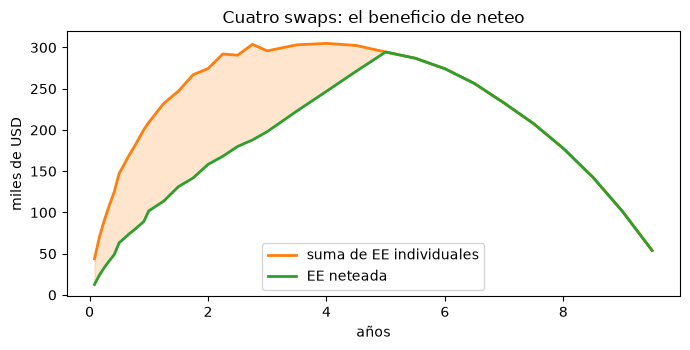

In [11]:
# Dibujar la suma de las cuatro EE individuales contra la EE del conjunto neteado
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(report, total / 1e3, color="tab:orange", lw=2, label="suma de EE individuales")
ax.plot(report, ee_net / 1e3, color="tab:green", lw=2, label="EE neteada")
ax.fill_between(report, ee_net / 1e3, total / 1e3, color="tab:orange", alpha=0.2)
ax.set_xlabel("años")
ax.set_ylabel("miles de USD")
ax.set_title("Cuatro swaps: el beneficio de neteo")
ax.legend()
fig.tight_layout()
plt.show()

La curva naranja suma las cuatro exposiciones como si cada swap se liquidara solo, la verde netea primero los valores, y la brecha sombreada es el beneficio de neteo. La brecha se abre pronto, porque los swaps que pagan en sentidos opuestos se anulan en la mayoría de las trayectorias, y se estrecha a plazos largos, donde solo vive el swap más largo y queda poco que netear. Léela como una afirmación sobre este libro: el caso armó las cuatro operaciones con sentidos que se compensan, y un libro de swaps del mismo sentido mostraría una banda mucho más delgada.

## Resultados

**Respuesta:** El swap pagador a 10 años llega a una exposición esperada máxima de 294.524 USD a los 5 años y a una exposición futura potencial de 95% de 901.804 USD a los 4,5 años; su promedio del primer año, la EEPE, es 87.551 USD. Neteado con los otros tres swaps, la exposición a un año baja de 209.175 USD (las cuatro exposiciones individuales sumadas) a 101.950 USD, un beneficio de 107.225 USD, más de la mitad de la suma.

- **El modelo reprecia la curva.** Los precios de bonos del modelo igualan los factores de descuento de la curva a 1e-16, la media muestral de la tasa corta simulada iguala a $\varphi(t)$ a 2e-14, y la dispersión de $r$ a 5 años (0,01356) es cercana al valor de Ornstein-Uhlenbeck (0,013705): la brecha es del orden del error de Monte Carlo de 20.000 trayectorias antitéticas. El término de convexidad $\varphi(t) - f(0,t)$ es pequeño a plazos cortos y crece hasta unos 9 pb a 10 años.
- **Un swap.** El pagador a 10 años paga 4,20% frente a una tasa par de 4,160%, así que parte bajo cero, en -32.701 USD. Su EE sube a medida que el valor se abre y cae a cero al vencimiento porque el swap se amortiza. La PFE de 95% alcanza su máximo antes y más alto: la PFE responde una pregunta de cola y la EE una de promedio.
- **Las medidas efectivas.** La EE crece durante el primer año, así que la EE efectiva es igual a la EE allí y la EPE es igual a la EEPE (87.551 USD, error de Monte Carlo 571). Serían distintas para un perfil que baja y vuelve a subir.
- **Neteo.** A 1 año las cuatro EE individuales suman 209.175 USD y la EE neteada es 101.950 USD. El beneficio llega a su máximo de 125.153 USD a 1,75 años. La suma de las EE individuales nunca está bajo la EE neteada, como exige la desigualdad sobre la parte positiva.

Lo que este notebook no muestra: cómo un acuerdo de garantías y un período de riesgo de margen cambian la exposición (notebook 02), cuánto cuesta la exposición en CVA (notebook 03), ni si el modelo merece confianza (notebooks 06 a 08).

## Resumen

- Un modelo de Hull-White de un factor, ajustado a la curva de hoy y a 35 años de la tasa corta, simula las tasas futuras; el swap se valora en cada trayectoria y fecha con los precios de bonos del propio modelo.
- La EE es el valor positivo promedio, la PFE un cuantil alto de él, la EPE y la EEPE sus promedios en el tiempo del primer año; Contraste las informa sin descontar, en la medida $t$-forward.
- El neteo actúa sobre la suma de los valores, así que la EE neteada es a lo más la suma de las EE individuales; aquí el beneficio es más de la mitad de la suma a un año.
- El error de Monte Carlo es pequeño frente a los efectos que se leen aquí: 571 USD sobre una EEPE de 87.551 USD.

**Qué probar después.** Cambia `seed` o `n_paths` en la celda de simulación y mira cómo se mueven los errores de Monte Carlo; valora solo SW-2 y SW-3 y mira cuánto neteo dan dos swaps que se compensan. Luego sigue con el notebook 02.

## Referencias

- BCBS, Basel Framework, CRE53 Internal model method for counterparty credit risk (in force 2023-01-01, published 2020-06-05). https://www.bis.org/basel_framework/chapter/CRE/53.htm?inforce=20230101&published=20200605
- Brigo, D., Dalessandro, A., Neugebauer, M. and Triki, F. (2008), A stochastic processes toolkit for risk management, arXiv 0812.4210. https://arxiv.org/abs/0812.4210
- Open Source Risk Engine, Methodology, value adjustments and margin period of risk (xva.tex at tag 1.8.17.0). https://github.com/OpenSourceRisk/Engine/blob/1.8.17.0/Docs/UserGuide/methods/xva.tex
- U.S. Department of the Treasury, Daily Treasury Par Yield Curve Rates. https://home.treasury.gov/resource-center/data-chart-center/interest-rates/